# Harmonization of MODIS and VIIRS hotspots
NASA Space Apps Challenge 2026 · *Harmonization of MODIS and VIIRS Hot Spots*

This notebook builds `tabla_armonizada.csv` (harmonized monthly hotspot counts per 0.25° cell, on the MODIS scale) and runs the uncertainty analysis used by the Streamlit app (`app.py`).

**Pipeline**
1. Load the raw FIRMS archive and near-real-time (NRT) files.
2. Filter by confidence and fire type.
3. Build the base table (cell × month × sensor).
4. Measure the VIIRS/MODIS jump and validate the conversion factor on years it never saw.
5. Build the harmonized table.
6. Quantify the uncertainty.

Note: the column names of the output CSV (`mes`, `conteo_eq`, `origen`, `provisorio`) and the file names are kept in Spanish because `app.py` reads them.

## 1. Load raw FIRMS files

In [1]:
import pandas as pd
from pathlib import Path

# Raw FIRMS archive downloads for Paraguay. Adjust `base` to the folder where you unzipped them.
base = Path.home() / "Downloads"

modis_arch = pd.read_csv(base / "DL_FIRE_M-C61_846041" / "fire_archive_M-C61_846041.csv")   # MODIS standard archive
modis_nrt  = pd.read_csv(base / "DL_FIRE_M-C61_846041" / "fire_nrt_M-C61_846041.csv")       # MODIS near-real-time
viirs_arch = pd.read_csv(base / "DL_FIRE_SV-C2_846046" / "fire_archive_SV-C2_846046.csv")   # VIIRS S-NPP standard archive
viirs_nrt  = pd.read_csv(base / "DL_FIRE_SV-C2_846046" / "fire_nrt_SV-C2_846046.csv")       # VIIRS S-NPP near-real-time

for name, d in [("MODIS arch", modis_arch), ("MODIS nrt", modis_nrt), ("VIIRS arch", viirs_arch), ("VIIRS nrt", viirs_nrt)]:
    print(name, d.shape, d.acq_date.min(), d.acq_date.max())
    print(d.columns.tolist())

print(modis_arch.satellite.value_counts())
print(viirs_arch.satellite.value_counts())
print(modis_arch.confidence.describe())
print(viirs_arch.confidence.value_counts())

MODIS arch (1058738, 15) 2000-11-01 2026-08-31
['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type']
MODIS nrt (5742, 14) 2026-09-01 2026-11-13
['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight']
VIIRS arch (1885831, 15) 2012-01-20 2026-07-31
['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type']
VIIRS nrt (24090, 14) 2026-08-01 2026-11-01
['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight']
satellite
Aqua     646850
Terra    411888
Name: count, dtype: int64
satellite
SNPP    1885831
Name: count, dtype: int64
count    1.058738e+

## 2. Filtering
Same criterion for both sensors: drop low-confidence detections (MODIS confidence < 30, VIIRS `l`) and keep only `type == 0` (presumed vegetation fire). NRT files have no `type` column, so only the confidence filter applies there. NRT is provisional and is flagged as such later.

In [2]:
# Quick look at the fields used by the filter
print(modis_arch.type.value_counts())
print(viirs_arch.type.value_counts())
print(modis_nrt.confidence.describe())
print(viirs_nrt.confidence.value_counts())
print("MODIS low (<30):", (modis_arch.confidence < 30).sum())
print("MODIS high (>=80):", (modis_arch.confidence >= 80).sum())
dup = ['latitude','longitude','acq_date','acq_time','satellite']
print("duplicates MODIS:", modis_arch.duplicated(dup).sum(), " VIIRS:", viirs_arch.duplicated(dup).sum())

type
0    1054512
2       4226
Name: count, dtype: int64
type
0    1884371
3       1146
2        314
Name: count, dtype: int64
count    5742.000000
mean       72.241553
std        19.702189
min         0.000000
25%        60.000000
50%        73.000000
75%        87.000000
max       100.000000
Name: confidence, dtype: float64
confidence
n    21143
l     1746
h     1201
Name: count, dtype: int64
MODIS low (<30): 37312
MODIS high (>=80): 345755
duplicates MODIS: 0  VIIRS: 2


In [3]:
dup = ['latitude','longitude','acq_date','acq_time','satellite']

modis_f     = modis_arch[(modis_arch.confidence >= 30) & (modis_arch.type == 0)].assign(file_source='archive')
viirs_f     = viirs_arch[viirs_arch.confidence.isin(['n','h']) & (viirs_arch.type == 0)].drop_duplicates(dup).assign(file_source='archive')
modis_nrt_f = modis_nrt[modis_nrt.confidence >= 30].assign(file_source='nrt')
viirs_nrt_f = viirs_nrt[viirs_nrt.confidence.isin(['n','h'])].assign(file_source='nrt')

for name, a, b in [("MODIS arch", modis_arch, modis_f), ("VIIRS arch", viirs_arch, viirs_f),
                   ("MODIS nrt", modis_nrt, modis_nrt_f), ("VIIRS nrt", viirs_nrt, viirs_nrt_f)]:
    print(name, len(a), "->", len(b), f"({len(b)/len(a):.1%})")

MODIS arch 1058738 -> 1017385 (96.1%)
VIIRS arch 1885831 -> 1724796 (91.5%)
MODIS nrt 5742 -> 5579 (97.2%)
VIIRS nrt 24090 -> 22344 (92.8%)


## 3. Base table (cell × month × sensor)
0.25° grid with the convention of the MODIS CMG product (`y = floor((90 − lat)/0.25)`, `x = floor((lon + 180)/0.25)`). Terra, Aqua and VIIRS S-NPP are kept separate here; what gets combined is decided in section 5.

In [4]:
import numpy as np

modis_all = pd.concat([modis_f, modis_nrt_f])
viirs_all = pd.concat([viirs_f, viirs_nrt_f])
print(modis_all.satellite.value_counts())   # check Terra/Aqua are also named this way in NRT
print(viirs_all.satellite.value_counts())

modis_all['sensor'] = 'MODIS_' + modis_all.satellite
viirs_all['sensor'] = 'VIIRS_SNPP'
det = pd.concat([modis_all, viirs_all])      # all detections after filtering

det['mes'] = pd.to_datetime(det.acq_date).dt.to_period('M').astype(str)
det['cy'] = np.floor((90 - det.latitude) / 0.25).astype(int)
det['cx'] = np.floor((det.longitude + 180) / 0.25).astype(int)

tabla = (det.groupby(['cy', 'cx', 'mes', 'sensor', 'file_source'])
            .size().rename('conteo').reset_index())

print(det.sensor.value_counts())
print(tabla.shape, tabla.cy.nunique() * tabla.cx.nunique(), "possible cells")
print(tabla.groupby('sensor').mes.agg(['min', 'max']))
tabla.to_csv('tabla_base.csv', index=False)

satellite
Aqua     626033
Terra    396931
Name: count, dtype: int64
satellite
SNPP    1747140
Name: count, dtype: int64
sensor
VIIRS_SNPP     1747140
MODIS_Aqua      626033
MODIS_Terra     396931
Name: count, dtype: int64
(215958, 6) 1156 possible cells
                 min      max
sensor                       
MODIS_Aqua   2002-07  2026-11
MODIS_Terra  2000-11  2026-11
VIIRS_SNPP   2012-01  2026-11


## 4. Measure the jump
VIIRS counts several times more detections than MODIS (375 m vs 1 km), so simply adding both sensors would create an artificial step in 2012. Here we measure it and then validate a conversion factor.

Note: the table only has rows with count > 0. Missing combinations are filled with 0 **only from the start of each sensor**; before that date they are "no data", not zero.

In [5]:
t = tabla.groupby(['mes', 'sensor']).conteo.sum().unstack(fill_value=0)
t.index = pd.PeriodIndex(t.index, freq='M')
t = t.reindex(pd.period_range('2000-11', '2026-11', freq='M'), fill_value=0)
t['MODIS'] = t.MODIS_Terra + t.MODIS_Aqua

# 1) yearly totals by sensor and VIIRS/MODIS ratio (2026 is incomplete)
annual = t.groupby(t.index.year).sum()
annual['VIIRS/MODIS'] = (annual.VIIRS_SNPP / annual.MODIS).where(annual.VIIRS_SNPP > 0).round(2)
print(annual)

# 2) VIIRS/MODIS ratio by calendar month, complete overlap years
overlap = t.loc['2013-01':'2025-12']
by_month = overlap.groupby(overlap.index.month)[['VIIRS_SNPP', 'MODIS']].sum()
print((by_month.VIIRS_SNPP / by_month.MODIS).round(2))

sensor  MODIS_Aqua  MODIS_Terra  VIIRS_SNPP  MODIS  VIIRS/MODIS
2000             0          948           0    948          NaN
2001             0        17720           0  17720          NaN
2002         27810        17777           0  45587          NaN
2003         45100        18246           0  63346          NaN
2004         30845        12377           0  43222          NaN
2005         31824        16186           0  48010          NaN
2006         30513        15122           0  45635          NaN
2007         39665        21623           0  61288          NaN
2008         26325        14485           0  40810          NaN
2009         19980        12170           0  32150          NaN
2010         25145        15057           0  40202          NaN
2011         24869        16823           0  41692          NaN
2012         20803        14116      109304  34919         3.13
2013         27266        20423      152174  47689         3.19
2014         15806        12929       92

### Out-of-sample test of the conversion factor
The monthly factor is calibrated on 2013–2019 and tested on 2020–2025, years the factor never saw.

In [6]:
cal = t.loc['2013-01':'2019-12']
f = cal.groupby(cal.index.month).VIIRS_SNPP.sum() / cal.groupby(cal.index.month).MODIS.sum()
print(f.round(2))

te = t.loc['2020-01':'2025-12'].copy()
te['VIIRS_eq'] = te.VIIRS_SNPP.values / te.index.month.map(f).values
print("total bias:", round(te.VIIRS_eq.sum() / te.MODIS.sum() - 1, 3))
print("mean monthly error:", round(((te.VIIRS_eq - te.MODIS).abs() / te.MODIS.where(te.MODIS > 0)).mean(), 3))
print("correlation:", round(te.VIIRS_eq.corr(te.MODIS), 3))

1     3.51
2     3.48
3     3.44
4     3.39
5     3.27
6     3.40
7     3.15
8     2.99
9     3.04
10    3.14
11    3.18
12    3.22
dtype: float64
total bias: 0.031
mean monthly error: 0.095
correlation: 0.993


### Regional check
The western Chaco and the eastern region have different fire regimes. If both stay close to the national result, one monthly factor works for the whole country. (The −57.7° cut is an approximation of the Paraguay River.)

In [7]:
def monthly(df):
    t = df.groupby(['mes', 'sensor']).size().unstack(fill_value=0)
    t.index = pd.PeriodIndex(t.index, freq='M')
    t = t.reindex(pd.period_range('2012-02', '2025-12', freq='M'), fill_value=0)
    t['MODIS'] = t.MODIS_Terra + t.MODIS_Aqua
    return t

for region, mask in [("Western (Chaco)", det.longitude < -57.7),
                     ("Eastern", det.longitude >= -57.7)]:
    t_r = monthly(det[mask])
    cal, te = t_r.loc[:'2019-12'], t_r.loc['2020-01':].copy()
    f = cal.groupby(cal.index.month).VIIRS_SNPP.sum() / cal.groupby(cal.index.month).MODIS.sum()
    te['viirs_eq'] = te.VIIRS_SNPP.values / te.index.month.map(f).values   # not `eq`: it clashes with DataFrame.eq
    print(region,
          "| bias:", round(te.viirs_eq.sum() / te.MODIS.sum() - 1, 3),
          "| mean error:", round(((te.viirs_eq - te.MODIS).abs() / te.MODIS.where(te.MODIS > 0)).mean(), 3),
          "| corr:", round(te.viirs_eq.corr(te.MODIS), 3))

Western (Chaco) | bias: 0.028 | mean error: 0.1 | corr: 0.991
Eastern | bias: -0.013 | mean error: 0.126 | corr: 0.994


## 5. Harmonized table
Design: one sensor per period, so the only splice point is 2012-02.

| Period | Source | `origen` |
|---|---|---|
| 2000-11 → 2002-06 | Terra only × monthly (Terra+Aqua)/Terra ratio of 2003–2004 | `Terra_estimado` (estimated, cannot be validated) |
| 2002-07 → 2012-01 | Observed MODIS (Terra + Aqua) | `MODIS` |
| 2012-02 → today | VIIRS ÷ monthly factor, calibrated on 2012-02 to 2025-12 | `VIIRS_eq` |

January 2012 stays on MODIS because VIIRS started on the 20th. Months from 2026-08 come from NRT and get `provisorio=True`.

In [8]:
tb = (tabla.groupby(['cy','cx','mes','sensor']).conteo.sum()
           .unstack(fill_value=0).reset_index())
tb['mes'] = pd.PeriodIndex(tb['mes'], freq='M')
tb['MODIS'] = tb.MODIS_Terra + tb.MODIS_Aqua

tot = tb.groupby('mes')[['VIIRS_SNPP','MODIS','MODIS_Terra']].sum()
cal_v = tot.loc['2012-02':'2025-12']
f_viirs = cal_v.groupby(cal_v.index.month).VIIRS_SNPP.sum() / cal_v.groupby(cal_v.index.month).MODIS.sum()
cal_t = tot.loc['2003-01':'2004-12']
f_terra = cal_t.groupby(cal_t.index.month).MODIS.sum() / cal_t.groupby(cal_t.index.month).MODIS_Terra.sum()

month_num = tb['mes'].dt.month
p_viirs, p_aqua = pd.Period('2012-02','M'), pd.Period('2002-07','M')
cond = [tb['mes'] >= p_viirs, tb['mes'] >= p_aqua]
tb['conteo_eq'] = np.select(cond, [tb.VIIRS_SNPP / month_num.map(f_viirs), tb.MODIS],
                            default=tb.MODIS_Terra * month_num.map(f_terra))
tb['origen'] = np.select(cond, ['VIIRS_eq','MODIS'], default='Terra_estimado')
tb['provisorio'] = tb['mes'] >= pd.Period('2026-08','M')

harm_series = tb.groupby('mes').conteo_eq.sum()
modis_series = tb.groupby('mes').MODIS.sum()
# Step check: the mean level change across 2012 should match MODIS alone.
# Caveat: this is partly true by construction, since the factor was calibrated on 2012-02..2025-12.
for ini, fin in [('2010-01','2011-12'), ('2012-02','2013-12')]:
    print(ini, fin, "harmonized:", round(harm_series.loc[ini:fin].mean()),
          "| MODIS only:", round(modis_series.loc[ini:fin].mean()))

tb[['cy','cx','mes','conteo_eq','origen','provisorio']].to_csv('tabla_armonizada.csv', index=False)

2010-01 2011-12 harmonized: 3412 | MODIS only: 3412
2012-02 2013-12 harmonized: 3450 | MODIS only: 3449


## 6. Uncertainty

### 6.1 First attempt (superseded)
Model tried first: `r² = a/N + b²` (counting noise plus a size-independent systematic part), fitted on the squared relative difference `r = (V − M)/N` between converted VIIRS (V) and MODIS (M), with `N = (V + M)/2`, binned by N.

**This model was rejected.** It gave `b ≈ 0.43`, a floor that the data contradict at large N, and it overestimated the observed `r²` by 1.5 to 9 times between N ≈ 30 and N ≈ 2,400. The consolidated analysis in 6.4 replaces it. The cells in 6.1 to 6.3 are kept as a record of the exploration.

In [9]:
import numpy as np

# monthly factor calibrated ONLY on 2012-02..2019-12; test on 2020-2025
cal = tb[(tb.mes >= pd.Period('2012-02','M')) & (tb.mes <= pd.Period('2019-12','M'))]
f = cal.groupby(cal.mes.dt.month).VIIRS_SNPP.sum() / cal.groupby(cal.mes.dt.month).MODIS.sum()

months = pd.period_range('2020-01', '2025-12', freq='M')
te = tb[(tb.mes >= months[0]) & (tb.mes <= months[-1])].copy()
te['V'] = te.VIIRS_SNPP / te.mes.dt.month.map(f)
te['M'] = te.MODIS

rows = []
for k in [1, 2, 4, 8, 17, 34]:            # block side, in cells
    te['by'], te['bx'] = te.cy // k, te.cx // k
    g = te.groupby(['by', 'bx', 'mes'])[['V', 'M']].sum()
    V = g.V.unstack(fill_value=0).reindex(columns=months, fill_value=0)
    M = g.M.unstack(fill_value=0).reindex(columns=months, fill_value=0)
    N = ((V + M) / 2).to_numpy().ravel()
    D = (V - M).to_numpy().ravel()
    ok = N > 0
    rows.append(pd.DataFrame({'k': k, 'N': N[ok], 'r': D[ok] / N[ok]}))
d = pd.concat(rows)

d['bin'] = pd.cut(d.N, [0, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 1e6])
s = d.groupby('bin', observed=True).agg(n=('r', 'size'), N=('N', 'mean'),
                                         bias=('r', 'mean'),
                                         r2=('r', lambda x: (x**2).mean()))
print(s.round(3))

# fit r2 = a/N + b^2, weighted by n  (rejected model, see the note above)
X = np.c_[1 / s.N, np.ones(len(s))]
w = np.sqrt(s.n.to_numpy())
(a, b2), *_ = np.linalg.lstsq(X * w[:, None], s.r2.to_numpy() * w, rcond=None)
print("a =", round(a, 2), "| b² =", round(b2, 4), "| b =", round(np.sqrt(max(b2, 0)), 3))

                         n         N   bias     r2
bin                                               
(0.0, 1.0]           11334     0.458  1.170  3.468
(1.0, 2.0]            5509     1.491  0.264  1.425
(2.0, 5.0]            8855     3.311  0.078  0.718
(5.0, 10.0]           6637     7.184  0.002  0.381
(10.0, 20.0]          5604    14.254 -0.021  0.237
(20.0, 50.0]          4910    31.411 -0.034  0.154
(50.0, 100.0]         2102    70.028 -0.025  0.106
(100.0, 200.0]        1149   141.360  0.004  0.077
(200.0, 500.0]         741   307.951  0.021  0.055
(500.0, 1000.0]        204   699.647  0.040  0.035
(1000.0, 1000000.0]    175  2425.813  0.046  0.021
a = 1.52 | b² = 0.1887 | b = 0.434


### 6.2 Terra-only months: sensitivity to the ratio window
The (Terra + Aqua)/Terra ratio is not stable over time, and the 20 Terra-only months (2000-11 to 2002-06) cannot be validated. This shows how much their total changes depending on which window sets the ratio.

In [10]:
tot = tb.groupby('mes')[['MODIS', 'MODIS_Terra']].sum()
tot.index = tot.index.to_timestamp()
annual = tot.loc['2003':'2011'].groupby(tot.loc['2003':'2011'].index.year).sum()
print((annual.MODIS / annual.MODIS_Terra).round(2))

terra_pre = tot.loc['2000-11':'2002-06'].MODIS_Terra.sum()
for name, years in [('2003-04 (the one used)', [2003, 2004]), ('2005-06', [2005, 2006]), ('2007-08', [2007, 2008])]:
    fac = annual.loc[years].MODIS.sum() / annual.loc[years].MODIS_Terra.sum()
    print(name, "factor", round(fac, 2), "-> total 2000-11..2002-06:", round(terra_pre * fac))

mes
2003    3.47
2004    3.49
2005    2.97
2006    3.02
2007    2.83
2008    2.82
2009    2.64
2010    2.67
2011    2.48
dtype: float64
2003-04 (the one used) factor 3.48 -> total 2000-11..2002-06: 76692
2005-06 factor 2.99 -> total 2000-11..2002-06: 65918
2007-08 factor 2.83 -> total 2000-11..2002-06: 62314


### 6.3 Inspect the saved table
Reads `tabla_armonizada.csv` back and plots the harmonized series for Paraguay. The red dashed lines mark 2002-07 (Aqua enters) and 2012-02 (splice with VIIRS). A step at either line would need investigation.

current folder: C:\Users\Administrador\Downloads
(114317, 8)
cy                int64
cx                int64
mes           period[M]
conteo_eq       float64
origen           object
provisorio         bool
lat             float64
lon             float64
dtype: object
    cy   cx      mes  conteo_eq    origen  provisorio     lat     lon
0  437  476  2017-08   0.994505  VIIRS_eq       False -19.375 -60.875
1  437  476  2021-05   0.293732  VIIRS_eq       False -19.375 -60.875
2  437  477  2002-11   2.000000     MODIS       False -19.375 -60.625
3  437  477  2002-12   2.000000     MODIS       False -19.375 -60.625
4  437  477  2008-12   1.000000     MODIS       False -19.375 -60.625
5  437  477  2010-12   1.000000     MODIS       False -19.375 -60.625
6  437  477  2012-11   0.000000  VIIRS_eq       False -19.375 -60.625
7  437  477  2012-12   0.000000  VIIRS_eq       False -19.375 -60.625
8  437  477  2013-04   0.000000  VIIRS_eq       False -19.375 -60.625
9  437  477  2013-06   0.301080  

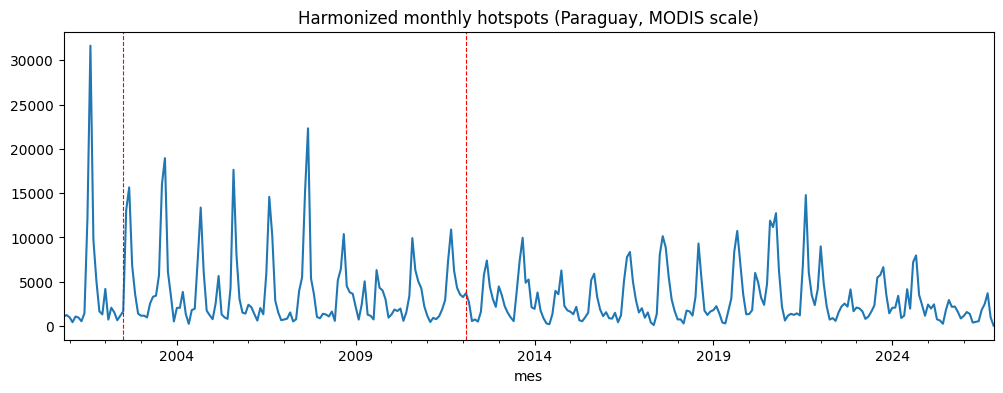

In [11]:
import os
import pandas as pd
import matplotlib.pyplot as plt

print("current folder:", os.getcwd())
df = pd.read_csv('tabla_armonizada.csv')
df['mes'] = pd.PeriodIndex(df['mes'], freq='M')
df['lat'] = 89.875 - 0.25 * df.cy       # cell centers
df['lon'] = -179.875 + 0.25 * df.cx

print(df.shape)
print(df.dtypes)
print(df.head(10))
print(df.origen.value_counts())
print(df.groupby('origen').mes.agg(['min', 'max']))
print("cells with hotspots:", df[['cy', 'cx']].drop_duplicates().shape[0])

series = df.groupby('mes').conteo_eq.sum()
series.index = series.index.to_timestamp()
ax = series.plot(figsize=(12, 4), title='Harmonized monthly hotspots (Paraguay, MODIS scale)')
for date in ['2002-07-01', '2012-02-01']:
    ax.axvline(pd.Timestamp(date), color='red', ls='--', lw=0.8)
plt.show()

### 6.3b Log-log fit on the binned table from 6.1 (first pass)
Fits `r² = c · N^p` using only bins with N ≥ 7. The consolidated cell in 6.4 repeats this fit step by step.

In [12]:
s7 = s[s.N >= 7]
p, lc = np.polyfit(np.log(s7.N), np.log(s7.r2), 1)
print("exponent p =", round(p, 2), "| c =", round(np.exp(lc), 2))

exponent p = -0.49 | c = 0.89


### 6.4 Consolidated uncertainty analysis (final)
Step by step. Definitions:
- `V` = VIIRS converted to the MODIS scale; `M` = MODIS (Terra + Aqua).
- `N = (V + M)/2` is the typical hotspot count of an area-period; `r = (V − M)/N` is the relative, symmetric difference.
- `MSE = mean(r²)`, `RMS = √MSE`. Bias share = `mean(r)² / MSE`.
- Fit `log(MSE) = log(c) + p·log(N)`, so `RMS(N) = √c · N^(p/2)`. The app uses `RMS ≈ 0.94 · N^−0.245`, valid for N ≥ 7.

The error measures how much converted VIIRS and MODIS disagree. It is not the error against actual fire.

In [13]:
import numpy as np, pandas as pd

# ---------- Base data (cell x month x sensor) ----------
if 'tb' not in globals():
    tabla = pd.read_csv('tabla_base.csv')
    tb = tabla.groupby(['cy','cx','mes','sensor']).conteo.sum().unstack(fill_value=0).reset_index()
    tb['mes'] = pd.PeriodIndex(tb['mes'], freq='M')
    tb['MODIS'] = tb.MODIS_Terra + tb.MODIS_Aqua

bins = [0, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 1e6]

# ---------- STEP 1: monthly factor (calibration only on 2012-02..2019-12) ----------
cal = tb[(tb.mes >= pd.Period('2012-02','M')) & (tb.mes <= pd.Period('2019-12','M'))]
f = cal.groupby(cal.mes.dt.month).VIIRS_SNPP.sum() / cal.groupby(cal.mes.dt.month).MODIS.sum()
print("STEP 1 · f = VIIRS/MODIS by calendar month:", f.round(2).to_dict())

# ---------- STEP 2: test set 2020-2025 on the MODIS scale ----------
months = pd.period_range('2020-01', '2025-12', freq='M')
te = tb[(tb.mes >= months[0]) & (tb.mes <= months[-1])].copy()
te['V'] = te.VIIRS_SNPP / te.mes.dt.month.map(f)
te['M'] = te.MODIS
print(f"\nSTEP 2 · {len(te)} test cell-month rows; V = VIIRS/f, M = MODIS (Terra+Aqua)")

# ---------- STEP 3: observations (N, r) aggregating cell blocks and month windows ----------
def observations(k, w=1):
    te['by'], te['bx'] = te.cy // k, te.cx // k
    g = te.groupby(['by','bx','mes'])[['V','M']].sum()
    V = g.V.unstack(fill_value=0).reindex(columns=months, fill_value=0)
    M = g.M.unstack(fill_value=0).reindex(columns=months, fill_value=0)
    if w > 1:
        V = V.T.groupby(np.arange(len(months)) // w).sum().T
        M = M.T.groupby(np.arange(len(months)) // w).sum().T
    N = ((V + M) / 2).to_numpy().ravel()
    D = (V - M).to_numpy().ravel()
    ok = N > 0
    return pd.DataFrame({'N': N[ok], 'r': D[ok] / N[ok]})

d = pd.concat([observations(k) for k in [1, 2, 4, 8, 17, 34]])
print(f"\nSTEP 3 · {len(d)} observations; N = (V+M)/2, r = (V-M)/N")

# ---------- STEP 4: MSE, RMS and bias share by N range ----------
def mse_table(d):
    d = d.assign(bin=pd.cut(d.N, bins))
    s = d.groupby('bin', observed=True).agg(n=('r','size'), N=('N','mean'),
                                             bias=('r','mean'),
                                             mse=('r', lambda x: (x**2).mean()))
    s['rms'] = np.sqrt(s.mse)
    s['bias2/mse'] = s.bias**2 / s.mse
    return s

s = mse_table(d)
print("\nSTEP 4 · MSE = mean(r²), RMS = √MSE, bias²/MSE = share of the error that is bias")
print(s.round(3))

# ---------- STEP 5: log-log fit (N >= 7): MSE = c · N^p ----------
def fit(s, Nmin=7):
    q = s[s.N >= Nmin]
    p, lc = np.polyfit(np.log(q.N), np.log(q.mse), 1)
    return p, np.exp(lc)

p, c = fit(s)
A, B = np.sqrt(c), p / 2
s['rms_model'] = A * s.N ** B
print(f"\nSTEP 5 · log(MSE) = log(c) + p·log(N) -> p = {p:.2f}, c = {c:.2f}")
print(f"         RMS(N) = √c · N^(p/2) = {A:.2f} · N^({B:.2f})")
print(s[['N', 'rms', 'rms_model']].round(3))

# ---------- STEP 6: uncertainty of the 20 Terra-only months ----------
tot = tb.groupby('mes')[['MODIS','MODIS_Terra']].sum()
tot.index = tot.index.to_timestamp()
annual = tot.loc['2003':'2011'].groupby(tot.loc['2003':'2011'].index.year).sum()
terra_pre = tot.loc['2000-11':'2002-06'].MODIS_Terra.sum()
est = {}
print("\nSTEP 6 · Terra-only months (not validatable): total depending on the window that sets the factor")
for name, years in [('2003-04 (used)', [2003, 2004]), ('2005-06', [2005, 2006]), ('2007-08', [2007, 2008])]:
    fac = annual.loc[years].MODIS.sum() / annual.loc[years].MODIS_Terra.sum()
    est[name] = terra_pre * fac
    print(f"   {name}: factor {fac:.2f} -> total {est[name]:,.0f}")
u = est['2003-04 (used)']
print(f"   range relative to the one used: {min(est.values())/u-1:+.0%} to {max(est.values())/u-1:+.0%}")
print("   (not a symmetric band: the ratio fell over time, so the true 2000-02 value could be equal or HIGHER than the one used)")

# ---------- STEP 7: ready-to-use formula and required N ----------
def uncertainty(N):
    return A * np.asarray(N, float) ** B

print("\nSTEP 7 · Expected error and required N")
for N in [10, 50, 100, 500, 1000, 5000]:
    print(f"   N = {N:>5} -> error ≈ {uncertainty(N):.0%}")
for e in [0.3, 0.2, 0.1]:
    print(f"   error {e:.0%} requires N ≈ {(A/e)**(-1/B):,.0f}")

# ---------- OPTIONS TO REDUCE THE UNCERTAINTY ----------
print("\n=== OPTIONS TO REDUCE THE UNCERTAINTY ===")

print("A) Aggregate over time (measured): does the same law hold when summing months?")
for w in [1, 3, 12]:
    dw = pd.concat([observations(k, w) for k in [1, 2, 4, 8, 17, 34]])
    pw, cw = fit(mse_table(dw))
    print(f"   window {w:>2} months: p = {pw:.2f}, c = {cw:.2f} | "
          f"RMS(N=100) = {np.sqrt(cw*100**pw):.0%} | RMS(N=1000) = {np.sqrt(cw*1000**pw):.0%}")

bias_share = s[s.N >= 10]['bias2/mse']
print(f"B) Recalibrate the factor (rolling or by region) (measured): it only removes bias = "
      f"{bias_share.min():.1%}-{bias_share.max():.1%} of the MSE for N ≥ 10; removing all of it would lower the RMS by at most {1-np.sqrt(1-bias_share.max()):.1%}")

print("C) Change what is counted (hypothesis, NOT measured): count fire-days per cell or clustered detections")
print("   instead of pixels, if the extra dispersion comes from clustering. Requires rebuilding the table.")
print("D) Terra-only months (not reducible): start the calendar in 2002-07 or show them as a range (STEP 6).")
print("E) Communicate (does not reduce, informs): show ± uncertainty(N) and flag 'low reliability' for N < 7.")

STEP 1 · f = VIIRS/MODIS by calendar month: {1: 3.51, 2: 3.52, 3: 3.46, 4: 3.44, 5: 3.4, 6: 3.45, 7: 3.19, 8: 3.01, 9: 3.05, 10: 3.12, 11: 3.21, 12: 3.24}

STEP 2 · 31002 test cell-month rows; V = VIIRS/f, M = MODIS (Terra+Aqua)

STEP 3 · 47220 observations; N = (V+M)/2, r = (V-M)/N

STEP 4 · MSE = mean(r²), RMS = √MSE, bias²/MSE = share of the error that is bias
                         n         N   bias    mse    rms  bias2/mse
bin                                                                 
(0.0, 1.0]           11334     0.458  1.170  3.468  1.862      0.395
(1.0, 2.0]            5509     1.491  0.264  1.425  1.194      0.049
(2.0, 5.0]            8855     3.311  0.078  0.718  0.848      0.008
(5.0, 10.0]           6637     7.184  0.002  0.381  0.617      0.000
(10.0, 20.0]          5604    14.254 -0.021  0.237  0.486      0.002
(20.0, 50.0]          4910    31.411 -0.034  0.154  0.393      0.007
(50.0, 100.0]         2102    70.028 -0.025  0.106  0.325      0.006
(100.0, 200.0